In [2]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path
from torchvision import transforms
import torchvision.transforms.functional as TF
import random

class RIMONEDataset(Dataset):
    def __init__(self, root_dir, split='treino', rot_limit=20, bright_limit=0.3):
        self.root_dir = Path(root_dir) / split
        self.split = split
        self.samples = []
        # Parâmetros que o Random Search vai controlar
        self.rot_limit = rot_limit
        self.bright_limit = bright_limit

        for classe in ['Glaucoma', 'Normal']:
            img_dir = self.root_dir / classe / 'Images'
            mask_dir = self.root_dir / classe / 'Masks'

            # LISTA TUDO UMA VEZ SÓ (Muito mais rápido no Drive)
            todas_mascaras = list(mask_dir.glob("*.png"))

            for img_path in img_dir.glob("*.png"):
                img_id = img_path.stem
                # Procura na lista local em vez de perguntar ao Drive de novo
                cup_path = [m for m in todas_mascaras if img_id in m.name and "Cup" in m.name]
                disc_path = [m for m in todas_mascaras if img_id in m.name and "Disc" in m.name]

                #cup_path = list(mask_dir.glob(f"*{img_id}*Cup*"))
                #disc_path = list(mask_dir.glob(f"*{img_id}*Disc*"))

                if cup_path and disc_path:
                    self.samples.append({
                        'image': img_path,
                        'cup': cup_path[0],
                        'disc': disc_path[0],
                        'label': 1 if classe == 'Glaucoma' else 0
                    })

    def transform(self, image, cup, disc, is_glaucoma):
        image = TF.resize(image, (224, 224), interpolation=transforms.InterpolationMode.BILINEAR)
        cup = TF.resize(cup, (224, 224), interpolation=transforms.InterpolationMode.NEAREST)
        disc = TF.resize(disc, (224, 224), interpolation=transforms.InterpolationMode.NEAREST)

        if self.split == 'treino':
            prob_base = 0.8 if is_glaucoma else 0.6

            # Flips (Mantemos fixos ou podemos otimizar também)
            if random.random() < prob_base:
                image = TF.hflip(image); cup = TF.hflip(cup); disc = TF.hflip(disc)
            if random.random() < prob_base:
                image = TF.vflip(image); cup = TF.vflip(cup); disc = TF.vflip(disc)

            # Rotação Otimizável
            if is_glaucoma or (random.random() < 0.5):
                angle = random.uniform(-self.rot_limit, self.rot_limit)
                image = TF.rotate(image, angle)
                cup = TF.rotate(cup, angle)
                disc = TF.rotate(disc, angle)

            # Brilho Otimizável (bright_limit ex: 0.3 vira range 0.7 a 1.3)
            if random.random() < prob_base:
                b_min, b_max = 1.0 - self.bright_limit, 1.0 + self.bright_limit
                brightness_factor = random.uniform(b_min, b_max)
                image = TF.adjust_brightness(image, brightness_factor)

        image = TF.to_tensor(image)
        cup = TF.to_tensor(cup)
        disc = TF.to_tensor(disc)
        mask = torch.cat([cup, disc], dim=0)
        mask = (mask > 0.5).float()

        return image, mask

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        amostra = self.samples[idx]
        img_pil = Image.open(amostra['image']).convert("RGB")
        cup_pil = Image.open(amostra['cup']).convert("L")
        disc_pil = Image.open(amostra['disc']).convert("L")
        img_tensor, mask_tensor = self.transform(img_pil, cup_pil, disc_pil, amostra['label'])
        return img_tensor, mask_tensor, amostra['label']
# Substitua pelo caminho que você copiou do seu Drive
#CAMINHO_BASE = "/content/drive/MyDrive/MESTRADO IFCE 2025/Dissertação(Implementação)/Implementações/RIM-ONE_DL_organizado2"

CAMINHO_BASE = "/home/daniel/Documents/Mestrado IFCE 2026/CONNEPI/CONNEPI/RIM-ONE_DL_organizado2"

# Criamos o objeto do dataset de treino
dataset_treino = RIMONEDataset(CAMINHO_BASE, split='treino')

print(f"Sucesso! O dataset de treino tem {len(dataset_treino)} pares de imagem/máscaras.")

Sucesso! O dataset de treino tem 311 pares de imagem/máscaras.


In [3]:
## Criação dos DataLoaders no Colab

from torch.utils.data import DataLoader

# 1. Definir o caminho.
# DICA: Se você descompactar o ZIP no Colab, o caminho será "/content/dataset_local"
# Se for ler direto do Drive, mantenha o caminho atual abaixo:
#CAMINHO_BASE = "/content/drive/MyDrive/MESTRADO IFCE 2025/Dissertação(Implementação)/Implementações/RIM-ONE_DL_organizado2"

CAMINHO_BASE = Path("/home/daniel/Documents/Mestrado IFCE 2026/SIBGRAPI/RIM-ONE_DL_organizado2")

# 2. Instanciar os Datasets
dataset_treino = RIMONEDataset(CAMINHO_BASE, split='treino')
dataset_teste = RIMONEDataset(CAMINHO_BASE, split='teste')

# 3. Configurações de Performance
BATCH_SIZE = 4 # No Colab, você pode tentar 16 ou até 32 com a TransUNet
NUM_WORKERS = 0 # O Colab funciona bem com 2 para evitar travamentos

if len(dataset_treino) > 0:
    train_loader = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    test_loader = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    print(f"🚀 DataLoaders prontos para o Colab!")
    print(f"📦 Batch Size: {BATCH_SIZE} | Workers: {NUM_WORKERS}")
    print(f"🖼️ Treino: {len(dataset_treino)} imagens | Teste: {len(dataset_teste)} imagens")
else:
    print("⚠️ Atenção: Verifique os caminhos no Google Drive!")

🚀 DataLoaders prontos para o Colab!
📦 Batch Size: 4 | Workers: 0
🖼️ Treino: 311 imagens | Teste: 174 imagens


In [4]:
import torch
import torch.nn as nn
from torchvision import models

# --- BLOCO 1: O BLOCO CONVOLUCIONAL BÁSICO ---
# Este bloco é o "tijolo" que constrói o decoder. Ele faz a convolução,
# normaliza os dados (Batch Norm) e aplica a ativação ReLU.
class Conv2dReLU(nn.Sequential):  ## nn.Sequential -> significa que as 3 funcoes serao executadas na ordem
    def __init__(self, in_channels, out_channels, kernel_size, padding=0, stride=1, use_batchnorm=True):
        # A convolução propriamente dita
        conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, bias=not (use_batchnorm))
        # Batch Norm ajuda a rede a treinar mais rápido e de forma mais estável
        bn = nn.BatchNorm2d(out_channels)
        # ReLU remove valores negativos, introduzindo a não-linearidade necessária
        relu = nn.ReLU(inplace=True)
        # super() inicializa a sequência de operações
        super(Conv2dReLU, self).__init__(conv, bn, relu)

# --- BLOCO 2: O DECODER (A RECONSTRUÇÃO) ---
# O Decoder é responsável por pegar os dados pequenos e profundos e "esticá-los"
# de volta ao tamanho 224x224, fundindo-os com as informações espaciais do Encoder.
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, skip_channels=0, use_batchnorm=True):
        super().__init__()
        # conv1 recebe a soma dos canais da camada anterior + canais da Skip Connection
        self.conv1 = Conv2dReLU(in_channels + skip_channels, out_channels, kernel_size=3, padding=1, use_batchnorm=use_batchnorm)
        # conv2 refina as características extraídas
        self.conv2 = Conv2dReLU(out_channels, out_channels, kernel_size=3, padding=1, use_batchnorm=use_batchnorm)
        # up aumenta o tamanho da imagem em 2x usando interpolação bilinear
        self.up = nn.UpsamplingBilinear2d(scale_factor=2)

    def forward(self, x, skip=None):
        # Primeiro, aumentamos a resolução do mapa de características
        x = self.up(x)
        # Se houver uma Skip Connection (conexão vinda do encoder), nós a grudamos aqui
        if skip is not None:
            x = torch.cat([x, skip], dim=1) # Concatenação no eixo dos canais
        # Passamos pelas convoluções para fundir os dados
        x = self.conv1(x)
        x = self.conv2(x)
        return x

# --- BLOCO 3: A ARQUITETURA TRANSUNET ---
class TransUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=2, embed_dim=768, num_heads=12, num_layers=12, dropout=0.1):
        super(TransUNet, self).__init__()

        # 1. ENCODER (RESNET50): Extrai características locais (bordas, texturas do disco)
        # Usamos pesos pré-treinados para aproveitar o conhecimento da rede em imagens reais
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        self.conv1 = resnet.conv1 # Primeira camada: reduz imagem para 112x112
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool # Reduz para 56x56

        # Guardamos as camadas da ResNet para servirem de Skip Connections
        self.encoder1 = resnet.layer1 # Saída: 256 canais (56x56)
        self.encoder2 = resnet.layer2 # Saída: 512 canais (28x28)
        self.encoder3 = resnet.layer3 # Saída: 1024 canais (14x14)
        self.encoder4 = resnet.layer4 # Saída: 2048 canais (7x7)

        # 2. BOTTLENECK (TRANSFORMER): Analisa a relação global (ex: Cup dentro do Disc)
        # Reduz os 2048 canais para 768 (tamanho padrão do Vision Transformer)
        self.vit_patch_embedding = nn.Conv2d(2048, embed_dim, kernel_size=1)

        # Camada de Transformer Encoder: onde a atenção acontece
        transformer_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads, dropout=dropout, batch_first=False)
        self.transformer_encoder = nn.TransformerEncoder(transformer_layer, num_layers=num_layers)

        # 3. DECODER: Reconstrói a máscara canal por canal
        # Cada camada reduz os canais e aumenta o tamanho (H, W)
        self.decoder4 = DecoderBlock(embed_dim, 1024, skip_channels=1024) # Recebe Transformer + skip3
        self.decoder3 = DecoderBlock(1024, 512, skip_channels=512)   # Recebe d4 + skip2
        self.decoder2 = DecoderBlock(512, 256, skip_channels=256)    # Recebe d3 + skip1
        self.decoder1 = DecoderBlock(256, 64, skip_channels=64)      # Recebe d2 + x0 (original)

        # Ajuste final para o tamanho original 224x224 e redução para 2 canais (Cup e Disc)
        self.final_up = nn.UpsamplingBilinear2d(scale_factor=2)
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # --- ETAPA ENCODER ---
        x0 = self.relu(self.bn1(self.conv1(x))) # Salva skip de baixa resolução
        x1 = self.maxpool(x0)

        skip1 = self.encoder1(x1) # Extração profunda 1
        skip2 = self.encoder2(skip1) # Extração profunda 2
        skip3 = self.encoder3(skip2) # Extração profunda 3 (última antes do bottleneck)

        # --- ETAPA TRANSFORMER ---
        vit_input = self.encoder4(skip3) # Características de alto nível
        vit_input_embedded = self.vit_patch_embedding(vit_input) # Ajusta canais para Transformer

        # O Transformer espera uma sequência linear (como palavras), por isso "achatamos" a imagem
        B, C, H, W = vit_input_embedded.shape
        vit_input_seq = vit_input_embedded.flatten(2).permute(2, 0, 1) # [seq_len, Batch, Embed_Dim]

        # Aplica a Atenção Global
        vit_output_seq = self.transformer_encoder(vit_input_seq)

        # Volta a sequência para o formato de imagem (tensor 4D)
        vit_output = vit_output_seq.permute(1, 2, 0).view(B, C, H, W)

        # --- ETAPA DECODER ---
        d4 = self.decoder4(vit_output, skip3) # Combina Transformer com skip3
        d3 = self.decoder3(d4, skip2) # Combina d4 com skip2
        d2 = self.decoder2(d3, skip1) # Combina d3 com skip1
        d1 = self.decoder1(d2, x0)    # Combina d2 com a primeira conv (detalhes finos)

        # --- FINALIZAÇÃO ---
        out = self.final_up(d1) # Garante que a saída tenha 224x224
        out = self.final_conv(out) # Resulta em [Batch, 2, 224, 224]
        return out

# --- INICIALIZAÇÃO NO AMBIENTE ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TransUNet(in_channels=3, out_channels=2).to(device)

print(f"🚀 Arquitetura TransUNet pronta e rodando em: {device}")

/tmp/ipykernel_4954/651822298.py:68: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(transformer_layer, num_layers=num_layers)


🚀 Arquitetura TransUNet pronta e rodando em: cuda


In [5]:
# --- 1. ATRIBUIÇÃO DOS NOVOS HIPERPARÂMETROS OTIMIZADOS ---
CONFIG_ESCOLHIDA = {
    'heads': 8,        # Alterado de 12 para 8 (muda a dinâmica das atenções globais)
    'layers': 6,       # Reduzido de 8 para 6 (ganho de velocidade + combate ao overfitting)
    'dropout': 0.2,    # Ajustado de 0.3 para 0.2
    'lr': 1e-4,        # Ajustado de 2e-4 para 1e-4 (treinamento mais suave e estável)
    'rot': 15,
    'bright': 0.3
}

In [6]:
import torch
import os

# --- DEFINIÇÃO DO DISPOSITIVO E INSTANCIAÇÃO DA TransUNet ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instancia a TransUNet (padrão de alta performance do artigo original)
model = TransUNet(
        in_channels=3, 
        out_channels=2,
        embed_dim=768,
        num_heads=CONFIG_ESCOLHIDA['heads'],
        num_layers=CONFIG_ESCOLHIDA['layers'],
        dropout=CONFIG_ESCOLHIDA['dropout']
    ).to(device)

# --- CAMINHO DO ARQUIVO .PTH DO HOLDOUT GERADO ANTERIORMENTE ---
PASTA_DESTINO = "/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/TransUnet/RIM_ONE_DL/MelhorModelo"
caminho_pesos = os.path.join(PASTA_DESTINO, "TransUNet_MELHOR_PESO_HOLDOUT.pth")

# --- CARREGAMENTO DOS PESOS ---
if os.path.exists(caminho_pesos):
    model.load_state_dict(torch.load(caminho_pesos, map_location=device))
    model.eval()
    print("✅ Pesos da TransUNet carregados com sucesso!")
    print("🚀 O modelo está pronto em modo de avaliação para extrair os atributos!")
else:
    print(f"❌ Erro: O arquivo de pesos não foi encontrado no caminho:\n📂 {caminho_pesos}")
    print("Verifique se o experimento de Hold-Out terminou corretamente.")

/tmp/ipykernel_4954/651822298.py:68: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(transformer_layer, num_layers=num_layers)


✅ Pesos da TransUNet carregados com sucesso!
🚀 O modelo está pronto em modo de avaliação para extrair os atributos!


In [7]:
from skimage.measure import label, regionprops
import numpy as np
import pandas as pd
import torch

def extrair_atributos_especialistas(model, loader, device):
    model.eval()
    dados_completos = []

    with torch.no_grad():
        for imagens, _, labels in loader:
            imagens = imagens.to(device)
            outputs = torch.sigmoid(model(imagens))
            preds = (outputs > 0.5).float().cpu().numpy()

            for i in range(preds.shape[0]):
                mask_cup = preds[i, 0, :, :]
                mask_disc = preds[i, 1, :, :]

                # --- 1. Áreas Básicas e CDR (Cup-to-Disc Ratio) ---
                area_cup = np.sum(mask_cup)
                area_disc = np.sum(mask_disc)
                area_cdr = area_cup / (area_disc + 1e-7)

                # --- 2. Borda Neurorretiniana (NRR) via Operação Lógica XOR ---
                # Borda = Disco Óptico XOR Escavação Óptica
                mask_nrr = np.logical_xor(mask_disc, mask_cup).astype(float)

                # --- 3. Propriedades Geométricas e Centroide ---
                props_disc = regionprops(label(mask_disc).astype(int))

                # Valores padrão para prevenções de erro de divisão
                rim_area_ratio_eq10 = 0.0
                r_s = r_i = r_n = r_t = 0.0

                if len(props_disc) > 0:
                    d = props_disc[0]

                    # --- 4. Divisão em Quadrantes ISNT (Inferior, Superior, Nasal, Temporal) ---
                    cy, cx = d.centroid
                    y, x = np.indices(mask_nrr.shape)
                    dy, dx = y - cy, x - cx

                    # Máscaras dos Quadrantes (Divisão em X)
                    mask_S = (mask_nrr > 0) & (dy < 0) & (np.abs(dx) <= np.abs(dy))
                    mask_I = (mask_nrr > 0) & (dy > 0) & (np.abs(dx) <= np.abs(dy))
                    mask_T = (mask_nrr > 0) & (dx < 0) & (np.abs(dy) <= np.abs(dx))
                    mask_N = (mask_nrr > 0) & (dx > 0) & (np.abs(dy) <= np.abs(dx))

                    # Áreas dos Setores da Borda normalizadas pela área total do Disco
                    r_s = np.sum(mask_S) / (area_disc + 1e-7)
                    r_i = np.sum(mask_I) / (area_disc + 1e-7)
                    r_n = np.sum(mask_N) / (area_disc + 1e-7)
                    r_t = np.sum(mask_T) / (area_disc + 1e-7)

                    # --- 5. Cálculo do Rim Area Ratio (Com Desvio Padrão ISNT) ---
                    std_si = np.std([r_s, r_i])
                    std_nt = np.std([r_n, r_t])
                    rim_area_ratio_eq10 = (1 + std_si) / (1 + std_nt + 1e-7)

                # Estruturação limpa contendo exclusivamente CDR e NRR
                dados_completos.append({
                    'area_cdr': area_cdr,
                    'nrr_superior': r_s,
                    'nrr_inferior': r_i,
                    'nrr_nasal': r_n,
                    'nrr_temporal': r_t,
                    'rim_area_ratio_eq10': rim_area_ratio_eq10,
                    'target': labels[i].item()
                })

    return pd.DataFrame(dados_completos)

# --- EXECUÇÃO ---
print("📊 Extraindo biomarcadores morfológicos (CDR e NRR)...")
df_expert_train = extrair_atributos_especialistas(model, train_loader, device)
df_expert_test  = extrair_atributos_especialistas(model, test_loader, device)

print("\n✅ Tabela de Atributos Extraídos (Primeiras linhas):")
print(df_expert_test.head())

📊 Extraindo biomarcadores morfológicos (CDR e NRR)...

✅ Tabela de Atributos Extraídos (Primeiras linhas):
   area_cdr  nrr_superior  nrr_inferior  nrr_nasal  nrr_temporal  \
0  0.266264      0.215338      0.225827   0.206153      0.086418   
1  0.485305      0.118156      0.148959   0.113358      0.134222   
2  0.292517      0.185194      0.165986   0.133814      0.222489   
3  0.334913      0.191062      0.114811   0.162327      0.196887   
4  0.525238      0.149359      0.083240   0.097940      0.144223   

   rim_area_ratio_eq10  target  
0             0.948463       1  
1             1.004918       1  
2             0.966741       1  
3             1.020491       1  
4             1.009694       1  


In [8]:
# Verificar balanceamento
print("📊 Distribuição das classes no treino:")
print(df_expert_train['target'].value_counts())

print("\n📊 Distribuição das classes no teste:")
print(df_expert_test['target'].value_counts())

# Calcular a porcentagem
print("\nProporção de Glaucoma (Classe 1) no treino:")
print(f"{df_expert_train['target'].mean() * 100:.2f}%")

📊 Distribuição das classes no treino:
target
0    195
1    116
Name: count, dtype: int64

📊 Distribuição das classes no teste:
target
0    118
1     56
Name: count, dtype: int64

Proporção de Glaucoma (Classe 1) no treino:
37.30%


In [9]:
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separação Original
X_train = df_expert_train.drop('target', axis=1)
y_train = df_expert_train['target']
X_test = df_expert_test.drop('target', axis=1)
y_test = df_expert_test['target']

# 2. Escalonamento (Indispensável para SVM e KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Aplicação do SMOTE para equilibrar as classes
#smote = SMOTE(sampling_strategy=1.0, random_state=42)  #SMOTE tradicional, mas com menos vizinhos. Ignora os outliers (Mais conservador)
smote = BorderlineSMOTE(sampling_strategy=1.0, random_state=42)  #Borderline-SMOTE (Focado em resolver a fronteira de decisão)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

# 4. Criação dos DataFrames Finais (Opcional, mas bom para organização)
# Treino balanceado
df_train_balanced = pd.DataFrame(X_train_res, columns=X_train.columns)
df_train_balanced['target'] = y_train_res

# Teste (não se aplica SMOTE no teste!)
df_test_final = pd.DataFrame(X_test_scaled, columns=X_test.columns)
df_test_final['target'] = y_test.values

print(f"✅ Novo DataFrame de treino gerado!")
print(f"Distribuição após SMOTE:\n{df_train_balanced['target'].value_counts()}")

✅ Novo DataFrame de treino gerado!
Distribuição após SMOTE:
target
0    195
1    195
Name: count, dtype: int64


In [10]:
df_total = pd.concat([df_train_balanced, df_test_final], axis=0)

In [11]:
from sklearn.model_selection import train_test_split

# ==============================================================================
# DIVISÃO DA BASE COMPLETA EM TREINO (70%) AND TESTE (30%) ESTRATIFICADO
# ==============================================================================

# 1. Separamos as colunas preditoras (X) e a coluna alvo (y) do nosso df_full
X = df_total[['area_cdr', 'rim_area_ratio_eq10']]
y = df_total['target']

# 2. Executamos o split oficial do sklearn
# test_size=0.25 garante os 25% para o teste real
# stratify=y força o algoritmo a manter a mesma proporção de glaucoma nas duas partições
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, 
    y, 
    test_size=0.30, 
    stratify=y, 
    random_state=42
)

# 3. Exibimos os tamanhos na tela para conferência rápida
print("🎉 Divisão 70/30 concluída com sucesso!")
print(f" -> Quantidade de amostras no Treino (K-Fold): {len(X_train_70)}")
print(f" -> Quantidade de amostras no Teste Independente: {len(X_test_30)}")
print(f" -> Proporção de Glaucoma no novo treino: {(y_train_70.mean() * 100):.2f}%")
print(f" -> Proporção de Glaucoma no novo teste:  {(y_test_30.mean() * 100):.2f}%")

🎉 Divisão 70/30 concluída com sucesso!
 -> Quantidade de amostras no Treino (K-Fold): 394
 -> Quantidade de amostras no Teste Independente: 170
 -> Proporção de Glaucoma no novo treino: 44.42%
 -> Proporção de Glaucoma no novo teste:  44.71%


📡 Iniciando Grid Search para o SVM (Total de combinações: 720)...
Fitting 5 folds for each of 360 candidates, totalling 1800 fits

🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA O SVM:
{'C': 0.0625, 'gamma': 2, 'kernel': 'rbf'}

🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...
💾 Relatório completo gravado com sucesso em 'resultados_svm_kfold_completo.txt'!

MÉTRICAS DA VALIDAÇÃO CRUZADA SVM (MÉDIA ± DESVIO PADRÃO EM %):
✅ Acurácia:       88.312% ± 2.891%
🎯 Precisão:       80.722% ± 3.733%
🚀 Sensibilidade:  97.143% ± 2.556%
🛡️  Especificidade: 81.247% ± 4.578%
💎 F1-Score:       88.124% ± 2.668%

Relatório de Classificação Final no Conjunto de Teste SVM (Mundo Real):
              precision    recall  f1-score   support

      Normal     0.9036    0.7979    0.8475        94
    Glaucoma     0.7816    0.8947    0.8344        76

    accuracy                         0.8412       170
   macro avg     0.8426    0.8463    0.8409       170
weighted avg     0.8491 

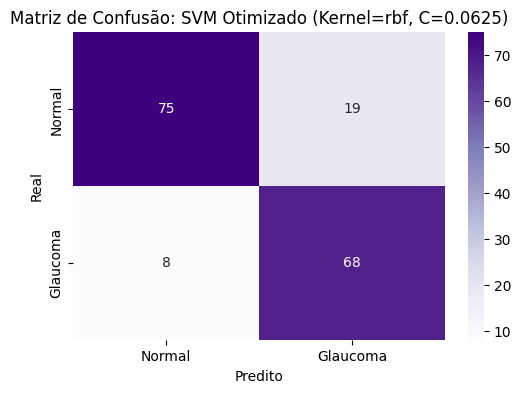

In [11]:
## Primeiro Classificador: SVM Otimizado com Grid Search Base 2, K-Fold (Média ± DP) e Avaliação de Teste

# Importa a biblioteca numpy para manipulação de arrays e cálculo de média/desvio padrão
import numpy as np
# Importa o seaborn para gerar visualizações de mapas de calor (matriz de confusão)
import seaborn as sns
# Importa o matplotlib para renderização e exibição de gráficos na tela
import matplotlib.pyplot as plt
# Importa o classificador SVM (Support Vector Classification) do scikit-learn
from sklearn.svm import SVC
# Importa o GridSearchCV para automação da busca exaustiva de hiperparâmetros
from sklearn.model_selection import GridSearchCV
# Importa a função cross_validate para computar múltiplas métricas simultaneamente no K-Fold
from sklearn.model_selection import cross_validate
# Importa o StratifiedKFold para garantir divisões proporcionais das classes em cada partição
from sklearn.model_selection import StratifiedKFold
# Importa as funções oficiais de geração de relatórios textuais e matrizes numéricas
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, make_scorer, recall_score

# ==============================================================================
# 1. DEFINIÇÃO DOS ATRIBUTOS E DAS BASES DE DADOS
# ==============================================================================

# Define a lista com os nomes exatos das colunas contendo os biomarcadores geométricos
#atributos_solidos = ['area_cdr', 'v_cdr', 'rim_area_ratio_eq10']

# Filtra a base de dados de treino balanceada mantendo apenas as colunas preditoras
#X_train = df_train_balanced[atributos_solidos]
X_train = X_train_70

# Extrai a coluna de rótulo alvo (0 para Normal, 1 para Glaucoma) da base de treino
#y_train = df_train_balanced['target']
y_train = y_train_70

# Filtra a base de teste final isolando os biomarcadores para a validação inédita
#X_test = df_test_final[atributos_solidos]
X_test = X_test_30

# Extrai os rótulos reais do conjunto de teste para servir de gabarito final
#y_test = df_test_final['target']
y_test = y_test_30


# ==============================================================================
# 2. CONFIGURAÇÃO E EXECUÇÃO DO GRID SEARCH (ESPAÇO DE BUSCA EM POTÊNCIAS DE 2)
# ==============================================================================

# Traduz o intervalo {2^-5, 2^-3, ..., 2^15} com passo de 2 em 2 no expoente
valores_c = [2**i for i in range(-5, 15, 1)]

# Traduz o intervalo {2^-15, 2^-13, ..., 2^3} com passo de 2 em 2 no expoente
valores_gamma = [2**i for i in range(-15, 3, 1)]

# Monta o dicionário exato com o espaço de busca da sua dissertação de referência
param_grid_svm = {
    'C': valores_c,
    'gamma': valores_gamma,
    'kernel': ['rbf']
}

print(f"📡 Iniciando Grid Search para o SVM (Total de combinações: {len(valores_c) * len(valores_gamma) * 2})...")

# Cria a instância do estimador SVM mantendo a semente fixa para reprodutibilidade
svm_base = SVC(probability=True, random_state=42)

# Configura o GridSearchCV focando na otimização da acurácia global com 5 folds
grid_search_svm = GridSearchCV(
    estimator=svm_base, param_grid=param_grid_svm, scoring='f1', cv=5, n_jobs=-1, verbose=1
)

# Executa o ajuste combinatório mapeando o melhor hiperparâmetro na base de treino
grid_search_svm.fit(X_train, y_train)

# Captura a estrutura do melhor modelo encontrado pelo processo de Grid Search
clf_svm = grid_search_svm.best_estimator_

print("\n🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA O SVM:")
print(grid_search_svm.best_params_)

# ==============================================================================
# 3. VALIDAÇÃO CRUZADA MULTI-MÉTRICA COM O MELHOR MODELO (MÉDIA ± DP EM %)
# ==============================================================================

print("\n🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...")

# Define um gerador de folds estratificado e embaralhado para manter a idoneidade estatística
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cria um scorer customizado para a Especificidade, focando no acerto da classe 0 (Normal)
especificidade_scorer = make_scorer(recall_score, pos_label=0)

# Cria o dicionário mapeando os identificadores oficiais para as métricas da sua tabela
metricas_solicitadas = {
    'acuracia': 'accuracy',
    'precisao': 'precision',
    'sensibilidade': 'recall',
    'especificidade': especificidade_scorer,
    'f1_score': 'f1'
}

# Executa o cross_validate computando simultaneamente todas as métricas em cada partição
resultados_cv = cross_validate(
    estimator=clf_svm,
    X=X_train,
    y=y_train,
    cv=cv_estratificado,
    scoring=metricas_solicitadas,
    return_train_score=False
)

# Extrai os arrays com as 5 notas, multiplicando por 100 para transformar em porcentagem (%)
folds_acc  = resultados_cv['test_acuracia'] * 100
folds_prec = resultados_cv['test_precisao'] * 100
folds_sens = resultados_cv['test_sensibilidade'] * 100
folds_esp  = resultados_cv['test_especificidade'] * 100
folds_f1   = resultados_cv['test_f1_score'] * 100

# ==============================================================================
# 4. INFERÊNCIA NO CONJUNTO DE TESTE INDEPENDENTE
# ==============================================================================

# Aplica o modelo final otimizado para gerar predições discretas na base de teste
y_pred_svm = clf_svm.predict(X_test)

# Calcula a matriz de confusão final para extração manual das métricas complementares
cm_svm = confusion_matrix(y_test, y_pred_svm)
tn, fp, fn, tp = cm_svm.ravel()
especificidade_teste = (tn / (tn + fp)) * 100

# ==============================================================================
# 5. GRAVAÇÃO COMPLETA DOS RESULTADOS EM ARQUIVO TEXTO .TXT
# ==============================================================================

# Abre o arquivo para escrita definindo codificação padrão universal
with open("resultados_svm_kfold_completo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("=====================================================================\n")
    arquivo.write("   RELATÓRIO DE VALIDAÇÃO CRUZADA E TESTE (SVM) - PORCENTAGEM (%)    \n")
    arquivo.write("=====================================================================\n\n")
    arquivo.write(f"Melhores Hiperparâmetros: {grid_search_svm.best_params_}\n\n")
    
    arquivo.write("Resultados Detalhados por Partição (Fold):\n")
    for i in range(5):
        arquivo.write(f" -> Fold {i+1}:\n")
        arquivo.write(f"    - Acurácia:       {folds_acc[i]:.3f}%\n")
        arquivo.write(f"    - Precisão:       {folds_prec[i]:.3f}%\n")
        arquivo.write(f"    - Sensibilidade:  {folds_sens[i]:.3f}%\n")
        arquivo.write(f"    - Especificidade: {folds_esp[i]:.3f}%\n")
        arquivo.write(f"    - F1-Score:       {folds_f1[i]:.3f}%\n\n")
        
    arquivo.write("=====================================================================\n")
    arquivo.write("MÉTRICAS CONSOLIDADAS DA VALIDAÇÃO CRUZADA (MÉDIA ± DP)\n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f" -> ACURÁCIA:       {np.mean(folds_acc):.3f}% (± {np.std(folds_acc):.3f}%)\n")
    arquivo.write(f" -> PRECISÃO:       {np.mean(folds_prec):.3f}% (± {np.std(folds_prec):.3f}%)\n")
    arquivo.write(f" -> SENSIBILIDADE:  {np.mean(folds_sens):.3f}% (± {np.std(folds_sens):.3f}%)\n")
    arquivo.write(f" -> ESPECIFICIDADE: {np.mean(folds_esp):.3f}% (± {np.std(folds_esp):.3f}%)\n")
    arquivo.write(f" -> F1-SCORE:       {np.mean(folds_f1):.3f}% (± {np.std(folds_f1):.3f}%)\n\n")
    
    arquivo.write("=====================================================================\n")
    arquivo.write("       AVALIAÇÃO NO CONJUNTO DE TESTE INDEPENDENTE (REAL)            \n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f"Acurácia no Teste:       {(accuracy_score(y_test, y_pred_svm)*100):.3f}%\n")
    arquivo.write(f"Especificidade no Teste: {especificidade_teste:.3f}%\n\n")
    arquivo.write("Relatório Detalhado de Classificação (Conjunto de Teste):\n")
    arquivo.write(classification_report(y_test, y_pred_svm, target_names=['Normal', 'Glaucoma'], digits=4))

print("💾 Relatório completo gravado com sucesso em 'resultados_svm_kfold_completo.txt'!")

# ==============================================================================
# 6. EXIBIÇÃO CONSOLIDADA DOS RESULTADOS NO TERMINAL
# ==============================================================================

print("\n" + "="*65)
print("MÉTRICAS DA VALIDAÇÃO CRUZADA SVM (MÉDIA ± DESVIO PADRÃO EM %):")
print("="*65)
print(f"✅ Acurácia:       {np.mean(folds_acc):.3f}% ± {np.std(folds_acc):.3f}%")
print(f"🎯 Precisão:       {np.mean(folds_prec):.3f}% ± {np.std(folds_prec):.3f}%")
print(f"🚀 Sensibilidade:  {np.mean(folds_sens):.3f}% ± {np.std(folds_sens):.3f}%")
print(f"🛡️  Especificidade: {np.mean(folds_esp):.3f}% ± {np.std(folds_esp):.3f}%")
print(f"💎 F1-Score:       {np.mean(folds_f1):.3f}% ± {np.std(folds_f1):.3f}%")
print("="*65)

print("\nRelatório de Classificação Final no Conjunto de Teste SVM (Mundo Real):")
print(classification_report(y_test, y_pred_svm, target_names=['Normal', 'Glaucoma'], digits=4))

# ==============================================================================
# 7. PLOT DA MATRIZ DE CONFUSÃO VISUAL
# ==============================================================================

kernel_otimo = grid_search_svm.best_params_['kernel']
c_otimo = grid_search_svm.best_params_['C']

plt.figure(figsize=(6,4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title(f"Matriz de Confusão: SVM Otimizado (Kernel={kernel_otimo}, C={c_otimo})")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

📡 Iniciando Grid Search para o KNN (K variando de 1 a 19)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

🏆 MELHORES HIPERPARAMETROS ENCONTRADOS:
{'metric': 'euclidean', 'n_neighbors': 17, 'weights': 'distance'}

🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...
💾 Relatório completo gravado com sucesso em 'resultados_knn_kfold_completo.txt'!

MÉTRICAS DA VALIDAÇÃO CRUZADA (MÉDIA ± DESVIO PADRÃO EM %):
✅ Acurácia:       87.809% ± 3.838%
🎯 Precisão:       82.546% ± 3.292%
🚀 Sensibilidade:  92.000% ± 6.363%
🛡️  Especificidade: 84.450% ± 3.175%
💎 F1-Score:       86.954% ± 4.362%

Relatório de Classificação Final no Conjunto de Teste (Mundo Real):
              precision    recall  f1-score   support

      Normal     0.8876    0.8404    0.8634        94
    Glaucoma     0.8148    0.8684    0.8408        76

    accuracy                         0.8529       170
   macro avg     0.8512    0.8544    0.8521       170
weighted avg     0.8551    

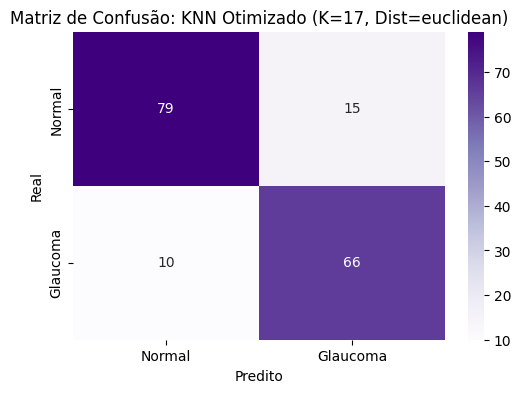

In [12]:
## Segundo Classificador: KNN Otimizado com K-Fold (Média ± DP) e Avaliação de Teste Completa

# Importa a biblioteca numpy para manipulação de arrays e cálculo de média/desvio padrão
import numpy as np
# Importa o seaborn para gerar visualizações de mapas de calor (matriz de confusão)
import seaborn as sns
# Importa o matplotlib para renderização e exibição de gráficos na tela
import matplotlib.pyplot as plt
# Importa o módulo math para operações matemáticas básicas, como a raiz quadrada
import math
# Importa o classificador KNN do ecossistema scikit-learn
from sklearn.neighbors import KNeighborsClassifier
# Importa o GridSearchCV para automação da busca exaustiva de hiperparâmetros
from sklearn.model_selection import GridSearchCV
# Importa a função cross_validate para computar múltiplas métricas simultaneamente no K-Fold
from sklearn.model_selection import cross_validate
# Importa o StratifiedKFold para garantir divisões profissionais das classes em cada partição
from sklearn.model_selection import StratifiedKFold
# Importa as funções oficiais de geração de relatórios textuais e matrizes numéricas
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, make_scorer, recall_score

# ==============================================================================
# 1. DEFINIÇÃO DOS ATRIBUTOS E DAS BASES DE DADOS
# ==============================================================================

# Define a lista com os nomes exatos das colunas contendo os biomarcadores geométricos
#atributos_solidos = ['area_cdr', 'v_cdr', 'rim_area_ratio_eq10']

# Filtra a base de dados de treino balanceada mantendo apenas as colunas preditoras
#X_train = df_train_balanced[atributos_solidos]
X_train = X_train_70

# Extrai a coluna de rótulo alvo (0 para Normal, 1 para Glaucoma) da base de treino
#y_train = df_train_balanced['target']
y_train = y_train_70

# Filtra a base de teste final isolando os biomarcadores para a validação inédita
#X_test = df_test_final[atributos_solidos]
X_test = X_test_30

# Extrai os rótulos reais do conjunto de teste para servir de gabarito final
#y_test = df_test_final['target']
y_test = y_test_30

# ==============================================================================
# 2. CONFIGURAÇÃO E EXECUÇÃO DO GRID SEARCH (BUSCA OTIMIZADA E LEVE)
# ==============================================================================

# Calcula a raiz quadrada do tamanho da amostra de treino (389) e arredonda para baixo
limite_k = math.floor(math.sqrt(394)) 

# Avalia se o limite numérico calculado resultou em um valor par
if limite_k % 2 == 0:
    # Subtrai uma unidade caso seja par, garantindo apenas valores ímpares contra empates
    limite_k -= 1

# Cria a lista restrita de vizinhos ímpares indo de 1 até o limite calculado inclusive
valores_k = list(range(1, limite_k + 1, 2))

# Monta a grade de parâmetros contendo a lista restrita, distâncias e lógica de pesos
param_grid = {
    'n_neighbors': valores_k,
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'weights': ['distance']
}

print(f"📡 Iniciando Grid Search para o KNN (K variando de 1 a {limite_k})...")

# Cria a instância vazia do estimador KNN para servir de base na busca combinatória
knn_base = KNeighborsClassifier()

# Configura o GridSearchCV focando na otimização da acurácia global com 5 folds
grid_search_knn = GridSearchCV(
    estimator=knn_base, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1, verbose=1
)

# Executa o ajuste combinatório mapeando o melhor hiperparâmetro na base de treino
grid_search_knn.fit(X_train, y_train)

# Captura a estrutura do melhor modelo encontrado pelo processo de Grid Search
clf_knn = grid_search_knn.best_estimator_

print("\n🏆 MELHORES HIPERPARAMETROS ENCONTRADOS:")
print(grid_search_knn.best_params_)

# ==============================================================================
# 3. VALIDAÇÃO CRUZADA MULTI-MÉTRICA COM O MELHOR MODELO (MÉDIA ± DP EM %)
# ==============================================================================

print("\n🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...")

# Define um gerador de folds estratificado e embaralhado para manter a idoneidade estatística
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cria um scorer customizado para a Especificidade, focando no acerto da classe 0 (Normal)
especificidade_scorer = make_scorer(recall_score, pos_label=0)

# Cria o dicionário mapeando os identificadores oficiais para as métricas da sua tabela
# Nota: 'recall' padrão foca na classe positiva (1), que matematicamente é a Sensibilidade
metricas_solicitadas = {
    'acuracia': 'accuracy',
    'precisao': 'precision',
    'sensibilidade': 'recall',
    'especificidade': especificidade_scorer,
    'f1_score': 'f1'
}

# Executa o cross_validate computando simultaneamente todas as métricas em cada partição
resultados_cv = cross_validate(
    estimator=clf_knn,
    X=X_train,
    y=y_train,
    cv=cv_estratificado,
    scoring=metricas_solicitadas,
    return_train_score=False
)

# Extrai os arrays com as 5 notas, multiplicando por 100 para transformar em porcentagem (%)
folds_acc  = resultados_cv['test_acuracia'] * 100
folds_prec = resultados_cv['test_precisao'] * 100
folds_sens = resultados_cv['test_sensibilidade'] * 100
folds_esp  = resultados_cv['test_especificidade'] * 100
folds_f1   = resultados_cv['test_f1_score'] * 100

# ==============================================================================
# 4. INFERÊNCIA NO CONJUNTO DE TESTE INDEPENDENTE
# ==============================================================================

# Aplica o modelo final otimizado para gerar predições discretas na base de teste
y_pred_knn = clf_knn.predict(X_test)
# Gera os scores de probabilidade contínua da classe positiva para monitoramento
y_scores_knn = clf_knn.predict_proba(X_test)[:, 1]

# Calcula a matriz de confusão final para extração manual das métricas complementares
cm = confusion_matrix(y_test, y_pred_knn)
tn, fp, fn, tp = cm.ravel()
especificidade_teste = (tn / (tn + fp)) * 100

# ==============================================================================
# 5. GRAVAÇÃO COMPLETA DOS RESULTADOS EM ARQUIVO TEXTO .TXT
# ==============================================================================

# Abre o arquivo para escrita definindo codificação padrão universal
with open("resultados_knn_kfold_completo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("=====================================================================\n")
    arquivo.write("   RELATÓRIO DE VALIDAÇÃO CRUZADA E TESTE - FORMATO PORCENTAGEM (%)  \n")
    arquivo.write("=====================================================================\n\n")
    arquivo.write(f"Melhores Hiperparâmetros: {grid_search_knn.best_params_}\n\n")
    
    arquivo.write("Resultados Detalhados por Partição (Fold):\n")
    for i in range(5):
        arquivo.write(f" -> Fold {i+1}:\n")
        arquivo.write(f"    - Acurácia:       {folds_acc[i]:.3f}%\n")
        arquivo.write(f"    - Precisão:       {folds_prec[i]:.3f}%\n")
        arquivo.write(f"    - Sensibilidade:  {folds_sens[i]:.3f}%\n")
        arquivo.write(f"    - Especificidade: {folds_esp[i]:.3f}%\n")
        arquivo.write(f"    - F1-Score:       {folds_f1[i]:.3f}%\n\n")
        
    arquivo.write("=====================================================================\n")
    arquivo.write("MÉTRICAS CONSOLIDADAS DA VALIDAÇÃO CRUZADA (MÉDIA ± DP)\n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f" -> ACURÁCIA:       {np.mean(folds_acc):.3f}% (± {np.std(folds_acc):.3f}%)\n")
    arquivo.write(f" -> PRECISÃO:       {np.mean(folds_prec):.3f}% (± {np.std(folds_prec):.3f}%)\n")
    arquivo.write(f" -> SENSIBILIDADE:  {np.mean(folds_sens):.3f}% (± {np.std(folds_sens):.3f}%)\n")
    arquivo.write(f" -> ESPECIFICIDADE: {np.mean(folds_esp):.3f}% (± {np.std(folds_esp):.3f}%)\n")
    arquivo.write(f" -> F1-SCORE:       {np.mean(folds_f1):.3f}% (± {np.std(folds_f1):.3f}%)\n\n")
    
    arquivo.write("=====================================================================\n")
    arquivo.write("       AVALIAÇÃO NO CONJUNTO DE TESTE INDEPENDENTE (REAL)            \n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f"Acurácia no Teste:       {(accuracy_score(y_test, y_pred_knn)*100):.3f}%\n")
    arquivo.write(f"Especificidade no Teste: {especificidade_teste:.3f}%\n\n")
    arquivo.write("Relatório Detalhado de Classificação (Conjunto de Teste):\n")
    arquivo.write(classification_report(y_test, y_pred_knn, target_names=['Normal', 'Glaucoma'], digits=4))

print("💾 Relatório completo gravado com sucesso em 'resultados_knn_kfold_completo.txt'!")

# ==============================================================================
# 6. EXIBIÇÃO CONSOLIDADA DOS RESULTADOS NO TERMINAL
# ==============================================================================

print("\n" + "="*65)
print("MÉTRICAS DA VALIDAÇÃO CRUZADA (MÉDIA ± DESVIO PADRÃO EM %):")
print("="*65)
print(f"✅ Acurácia:       {np.mean(folds_acc):.3f}% ± {np.std(folds_acc):.3f}%")
print(f"🎯 Precisão:       {np.mean(folds_prec):.3f}% ± {np.std(folds_prec):.3f}%")
print(f"🚀 Sensibilidade:  {np.mean(folds_sens):.3f}% ± {np.std(folds_sens):.3f}%")
print(f"🛡️  Especificidade: {np.mean(folds_esp):.3f}% ± {np.std(folds_esp):.3f}%")
print(f"💎 F1-Score:       {np.mean(folds_f1):.3f}% ± {np.std(folds_f1):.3f}%")
print("="*65)

print("\nRelatório de Classificação Final no Conjunto de Teste (Mundo Real):")
print(classification_report(y_test, y_pred_knn, target_names=['Normal', 'Glaucoma'], digits=4))

# ==============================================================================
# 7. PLOT DA MATRIZ DE CONFUSÃO VISUAL
# ==============================================================================

k_otimo = grid_search_knn.best_params_['n_neighbors']
metrica_otima = grid_search_knn.best_params_['metric']

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title(f"Matriz de Confusão: KNN Otimizado (K={k_otimo}, Dist={metrica_otima})")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

📡 Iniciando Grid Search para a Rede Neural MLP...
Fitting 5 folds for each of 160 candidates, totalling 800 fits


/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/daniel/Documents/Mestrado IFCE 2026/SBESC 2026/venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochast


🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA A MLP:
{'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (100,), 'learning_rate_init': 0.05, 'max_iter': 1000}

🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...
💾 Relatório completo gravado com sucesso em 'resultados_mlp_kfold_completo.txt'!

MÉTRICAS DA VALIDAÇÃO CRUZADA MLP (MÉDIA ± DESVIO PADRÃO EM %):
✅ Acurácia:       86.780% ± 4.603%
🎯 Precisão:       81.426% ± 5.461%
🚀 Sensibilidade:  91.429% ± 5.714%
🛡️  Especificidade: 83.066% ± 5.668%
💎 F1-Score:       86.040% ± 4.698%

Relatório de Classificação Final no Conjunto de Teste MLP (Mundo Real):
              precision    recall  f1-score   support

      Normal     0.9062    0.9255    0.9158        94
    Glaucoma     0.9054    0.8816    0.8933        76

    accuracy                         0.9059       170
   macro avg     0.9058    0.9036    0.9046       170
weighted avg     0.9059    0.9059    0.9058       170



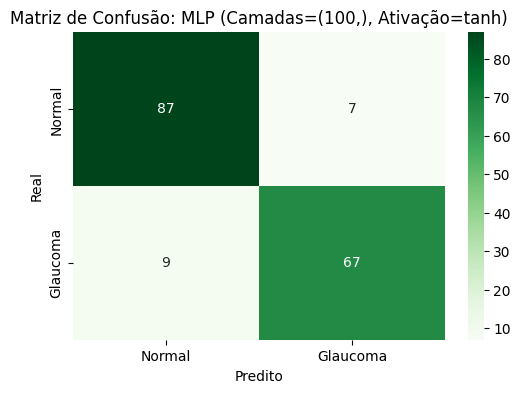

In [12]:
## Terceiro Classificador: MLP (Rede Neural Rasa) Otimizada com K-Fold (Média ± DP) e Avaliação de Teste Completa

# Importa a biblioteca numpy para manipulação de arrays e cálculo de média/desvio padrão
import numpy as np
# Importa o seaborn para gerar visualizações de mapas de calor (matriz de confusão)
import seaborn as sns
# Importa o matplotlib para renderização e exibição de gráficos na tela
import matplotlib.pyplot as plt
# Importa o classificador MLP (Multi-Layer Perceptron) do ecossistema scikit-learn
from sklearn.neural_network import MLPClassifier
# Importa o GridSearchCV para automação da busca exaustiva de hiperparâmetros
from sklearn.model_selection import GridSearchCV
# Importa a função cross_validate para computar múltiplas métricas simultaneamente no K-Fold
from sklearn.model_selection import cross_validate
# Importa o StratifiedKFold para garantir divisões profissionais das classes em cada partição
from sklearn.model_selection import StratifiedKFold
# Importa as funções oficiais de geração de relatórios textuais e matrizes numéricas
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, make_scorer, recall_score

# ==============================================================================
# 1. DEFINIÇÃO DOS ATRIBUTOS E DAS BASES DE DADOS
# ==============================================================================

X_train = X_train_70
y_train = y_train_70
X_test = X_test_30
y_test = y_test_30

# ==============================================================================
# 2. CONFIGURAÇÃO E EXECUÇÃO DO GRID SEARCH (MLP OTIMIZADA)
# ==============================================================================

# Monta a grade de parâmetros testando diferentes arquiteturas de neurônios e ativações
param_grid = {
    'hidden_layer_sizes': [(50,), (30, 20), (100,), (50, 25)], # Testando também duas camadas mais enxutas
    'activation': ['relu', 'tanh'],
    'learning_rate_init': [0.0001, 0.001, 0.005, 0.01, 0.05], # Espaço de busca da Taxa de Aprendizado Inicial expandido
    'alpha': [0.0001, 0.001, 0.01, 0.1],                     # Espaço de regularização L2 expandido
    'max_iter': [1000]
}

print("📡 Iniciando Grid Search para a Rede Neural MLP...")

# Cria a instância básica da MLP definindo o otimizador estável 'adam' e o random_state
mlp_base = MLPClassifier(solver='adam', random_state=42)

# Configura o GridSearchCV focando na otimização do F1-Score com 5 folds
grid_search_mlp = GridSearchCV(
    estimator=mlp_base, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1, verbose=1
)

# Executa o ajuste combinatório mapeando o melhor hiperparâmetro na base de treino
grid_search_mlp.fit(X_train, y_train)

# Captura a estrutura do melhor modelo encontrado pelo processo de Grid Search
clf_mlp = grid_search_mlp.best_estimator_

print("\n🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA A MLP:")
print(grid_search_mlp.best_params_)

# ==============================================================================
# 3. VALIDAÇÃO CRUZADA MULTI-MÉTRICA COM O MELHOR MODELO (MÉDIA ± DP EM %)
# ==============================================================================

print("\n🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...")

# Define um gerador de folds estratificado e embaralhado para manter a idoneidade estatística
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cria um scorer customizado para a Especificidade, focando no acerto da classe 0 (Normal)
especificidade_scorer = make_scorer(recall_score, pos_label=0)

# Cria o dicionário mapeando os identificadores oficiais para as métricas da sua tabela
metricas_solicitadas = {
    'acuracia': 'accuracy',
    'precisao': 'precision',
    'sensibilidade': 'recall',
    'especificidade': especificidade_scorer,
    'f1_score': 'f1'
}

# Executa o cross_validate computando simultaneamente todas as métricas em cada partição
resultados_cv = cross_validate(
    estimator=clf_mlp,
    X=X_train,
    y=y_train,
    cv=cv_estratificado,
    scoring=metricas_solicitadas,
    return_train_score=False
)

# Extrai os arrays com as 5 notas, multiplicando por 100 para transformar em porcentagem (%)
folds_acc  = resultados_cv['test_acuracia'] * 100
folds_prec = resultados_cv['test_precisao'] * 100
folds_sens = resultados_cv['test_sensibilidade'] * 100
folds_esp  = resultados_cv['test_especificidade'] * 100
folds_f1   = resultados_cv['test_f1_score'] * 100

# ==============================================================================
# 4. INFERÊNCIA NO CONJUNTO DE TESTE INDEPENDENTE
# ==============================================================================

# Aplica o modelo final otimizado para gerar predições discretas na base de teste
y_pred_mlp = clf_mlp.predict(X_test)
# Gera os scores de probabilidade contínua para monitoramento
y_scores_mlp = clf_mlp.predict_proba(X_test)[:, 1]

# Calcula a matriz de confusão final para extração manual das métricas complementares
cm = confusion_matrix(y_test, y_pred_mlp)
tn, fp, fn, tp = cm.ravel()
especificidade_teste = (tn / (tn + fp)) * 100

# ==============================================================================
# 5. GRAVAÇÃO COMPLETA DOS RESULTADOS EM ARQUIVO TEXTO .TXT
# ==============================================================================

# Abre o arquivo para escrita definindo codificação padrão universal
with open("resultados_mlp_kfold_completo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("=====================================================================\n")
    arquivo.write("    RELATÓRIO DE VALIDAÇÃO CRUZADA E TESTE MLP - PORCENTAGEM (%)     \n")
    arquivo.write("=====================================================================\n\n")
    arquivo.write(f"Melhores Hiperparâmetros: {grid_search_mlp.best_params_}\n\n")
    
    arquivo.write("Resultados Detalhados por Partição (Fold):\n")
    for i in range(5):
        arquivo.write(f" -> Fold {i+1}:\n")
        arquivo.write(f"    - Acurácia:       {folds_acc[i]:.3f}%\n")
        arquivo.write(f"    - Precisão:       {folds_prec[i]:.3f}%\n")
        arquivo.write(f"    - Sensibilidade:  {folds_sens[i]:.3f}%\n")
        arquivo.write(f"    - Especificidade: {folds_esp[i]:.3f}%\n")
        arquivo.write(f"    - F1-Score:       {folds_f1[i]:.3f}%\n\n")
        
    arquivo.write("=====================================================================\n")
    arquivo.write("MÉTRICAS CONSOLIDADAS DA VALIDAÇÃO CRUZADA MLP (MÉDIA ± DP)\n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f" -> ACURÁCIA:       {np.mean(folds_acc):.3f}% (± {np.std(folds_acc):.3f}%)\n")
    arquivo.write(f" -> PRECISÃO:       {np.mean(folds_prec):.3f}% (± {np.std(folds_prec):.3f}%)\n")
    arquivo.write(f" -> SENSIBILIDADE:  {np.mean(folds_sens):.3f}% (± {np.std(folds_sens):.3f}%)\n")
    arquivo.write(f" -> ESPECIFICIDADE: {np.mean(folds_esp):.3f}% (± {np.std(folds_esp):.3f}%)\n")
    arquivo.write(f" -> F1-SCORE:       {np.mean(folds_f1):.3f}% (± {np.std(folds_f1):.3f}%)\n\n")
    
    arquivo.write("=====================================================================\n")
    arquivo.write("       AVALIAÇÃO NO CONJUNTO DE TESTE INDEPENDENTE (REAL)            \n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f"Acurácia no Teste:       {(accuracy_score(y_test, y_pred_mlp)*100):.3f}%\n")
    arquivo.write(f"Especificidade no Teste: {especificidade_teste:.3f}%\n\n")
    arquivo.write("Relatório Detalhado de Classificação (Conjunto de Teste):\n")
    arquivo.write(classification_report(y_test, y_pred_mlp, target_names=['Normal', 'Glaucoma'], digits=4))

print("💾 Relatório completo gravado com sucesso em 'resultados_mlp_kfold_completo.txt'!")

# ==============================================================================
# 6. EXIBIÇÃO CONSOLIDADA DOS RESULTADOS NO TERMINAL
# ==============================================================================

print("\n" + "="*65)
print("MÉTRICAS DA VALIDAÇÃO CRUZADA MLP (MÉDIA ± DESVIO PADRÃO EM %):")
print("="*65)
print(f"✅ Acurácia:       {np.mean(folds_acc):.3f}% ± {np.std(folds_acc):.3f}%")
print(f"🎯 Precisão:       {np.mean(folds_prec):.3f}% ± {np.std(folds_prec):.3f}%")
print(f"🚀 Sensibilidade:  {np.mean(folds_sens):.3f}% ± {np.std(folds_sens):.3f}%")
print(f"🛡️  Especificidade: {np.mean(folds_esp):.3f}% ± {np.std(folds_esp):.3f}%")
print(f"💎 F1-Score:       {np.mean(folds_f1):.3f}% ± {np.std(folds_f1):.3f}%")
print("="*65)

print("\nRelatório de Classificação Final no Conjunto de Teste MLP (Mundo Real):")
print(classification_report(y_test, y_pred_mlp, target_names=['Normal', 'Glaucoma'], digits=4))

# ==============================================================================
# 7. PLOT DA MATRIZ DE CONFUSÃO VISUAL
# ==============================================================================

camadas = grid_search_mlp.best_params_['hidden_layer_sizes']
ativacao = grid_search_mlp.best_params_['activation']

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title(f"Matriz de Confusão: MLP (Camadas={camadas}, Ativação={ativacao})")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

📡 Iniciando Grid Search para o Random Forest...
Fitting 5 folds for each of 880 candidates, totalling 4400 fits

🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA O RANDOM FOREST:
{'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 13}

🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...
💾 Relatório completo gravado com sucesso em 'resultados_rf_kfold_completo.txt'!

MÉTRICAS DA VALIDAÇÃO CRUZADA RANDOM FOREST (MÉDIA ± DESVIO PADRÃO EM %):
✅ Acurácia:       87.549% ± 3.595%
🎯 Precisão:       82.879% ± 3.987%
🚀 Sensibilidade:  90.857% ± 4.571%
🛡️  Especificidade: 84.905% ± 3.835%
💎 F1-Score:       86.644% ± 3.799%

Relatório de Classificação Final no Conjunto de Teste RF (Mundo Real):
              precision    recall  f1-score   support

      Normal     0.9341    0.9043    0.9189        94
    Glaucoma     0.8861    0.9211    0.9032        76

    accuracy                         0.9118       170
   macro avg     0.9101    0.9127    0.

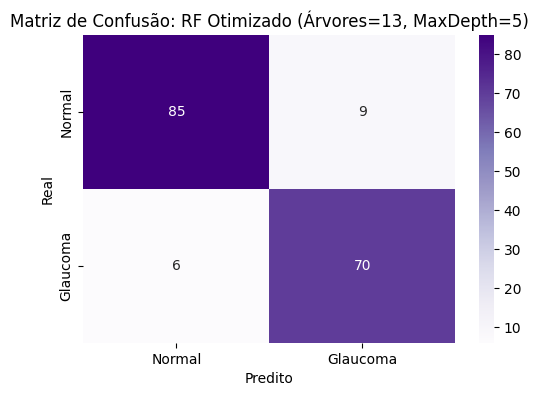

In [13]:
## Quarto Classificador: Random Forest Otimizado com Grid Search, K-Fold (Média ± DP) e Avaliação de Teste

# Importa a biblioteca numpy para manipulação de arrays e cálculo de média/desvio padrão
import numpy as np
# Importa o seaborn para gerar visualizações de mapas de calor (matriz de confusão)
import seaborn as sns
# Importa o matplotlib para renderização e exibição de gráficos na tela
import matplotlib.pyplot as plt
# Importa o classificador Random Forest do scikit-learn
from sklearn.ensemble import RandomForestClassifier
# Importa o GridSearchCV para automação da busca exaustiva de hiperparâmetros
from sklearn.model_selection import GridSearchCV
# Importa a função cross_validate para computar múltiplas métricas simultaneamente no K-Fold
from sklearn.model_selection import cross_validate
# Importa o StratifiedKFold para garantir divisões proporcionais das classes em cada partição
from sklearn.model_selection import StratifiedKFold
# Importa as funções oficiais de geração de relatórios textuais e matrizes numéricas
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, make_scorer, recall_score

# ==============================================================================
# 1. DEFINIÇÃO DOS ATRIBUTOS E DAS BASES DE DADOS
# ==============================================================================

# Define a lista com os nomes exatos das colunas contendo os biomarcadores geométricos
#atributos_solidos = ['area_cdr', 'v_cdr', 'rim_area_ratio_eq10']

# Filtra a base de dados de treino balanceada mantendo apenas as colunas preditoras
#X_train = df_train_balanced[atributos_solidos]
X_train = X_train_70

# Extrai a coluna de rótulo alvo (0 para Normal, 1 para Glaucoma) da base de treino
#y_train = df_train_balanced['target']
y_train = y_train_70

# Filtra a base de teste final isolando os biomarcadores para a validação inédita
#X_test = df_test_final[atributos_solidos]
X_test = X_test_30

# Extrai os rótulos reais do conjunto de teste para servir de gabarito final
#y_test = df_test_final['target']
y_test = y_test_30

# ==============================================================================
# 2. CONFIGURAÇÃO E EXECUÇÃO DO GRID SEARCH (ESPAÇO DE BUSCA PARA RANDOM FOREST)
# ==============================================================================

# Monta a grade de hiperparâmetros para refinar a estrutura das árvores da floresta
"""param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}"""

# 2. Monta o espaço de busca exatamente como você pensou
param_grid_rf = {
    'n_estimators': list(range(10, 30, 1)),      # 10 a 30, pulando de 1 em 1
    'max_depth': list(range(5, 16, 1)),            # 5 a 15, pulando de 2 em 2
    'min_samples_split': [2, 3, 4, 5],               # Discreto
    'criterion': ['gini']               # Discreto
}

print("📡 Iniciando Grid Search para o Random Forest...")

# Cria a instância básica da Random Forest fixando o random_state para reprodutibilidade
rf_base = RandomForestClassifier(random_state=42)

# Configura o GridSearchCV focando na otimização da f1-score global com 5 folds
grid_search_rf = GridSearchCV(
    estimator=rf_base, param_grid=param_grid_rf, scoring='f1', cv=5, n_jobs=-1, verbose=1
)

# Executa o ajuste combinatório mapeando os melhores parâmetros na base de treino
grid_search_rf.fit(X_train, y_train)

# Captura a estrutura do melhor modelo encontrado pelo processo de Grid Search
clf_rf = grid_search_rf.best_estimator_

print("\n🏆 MELHORES HIPERPARAMETROS ENCONTRADOS PARA O RANDOM FOREST:")
print(grid_search_rf.best_params_)

# ==============================================================================
# 3. VALIDAÇÃO CRUZADA MULTI-MÉTRICA COM O MELHOR MODELO (MÉDIA ± DP EM %)
# ==============================================================================

print("\n🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...")

# Define um gerador de folds estratificado e embaralhado para manter a idoneidade estatística
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cria um scorer customizado para a Especificidade, focando no acerto da classe 0 (Normal)
especificidade_scorer = make_scorer(recall_score, pos_label=0)

# Cria o dicionário mapeando os identificadores oficiais para as métricas da sua tabela
metricas_solicitadas = {
    'acuracia': 'accuracy',
    'precisao': 'precision',
    'sensibilidade': 'recall',
    'especificidade': especificidade_scorer,
    'f1_score': 'f1'
}

# Executa o cross_validate computando simultaneamente todas as métricas em cada partição
resultados_cv = cross_validate(
    estimator=clf_rf,
    X=X_train,
    y=y_train,
    cv=cv_estratificado,
    scoring=metricas_solicitadas,
    return_train_score=False
)

# Extrai os arrays com as 5 notas, multiplicando por 100 para transformar em porcentagem (%)
folds_acc  = resultados_cv['test_acuracia'] * 100
folds_prec = resultados_cv['test_precisao'] * 100
folds_sens = resultados_cv['test_sensibilidade'] * 100
folds_esp  = resultados_cv['test_especificidade'] * 100
folds_f1   = resultados_cv['test_f1_score'] * 100

# ==============================================================================
# 4. INFERÊNCIA NO CONJUNTO DE TESTE INDEPENDENTE
# ==============================================================================

# Aplica o modelo final otimizado para gerar predições discretas na base de teste
y_pred_rf = clf_rf.predict(X_test)

# Calcula a matriz de confusão final para extração manual das métricas complementares
cm_rf = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm_rf.ravel()
especificidade_teste = (tn / (tn + fp)) * 100

# ==============================================================================
# 5. GRAVAÇÃO COMPLETA DOS RESULTADOS EM ARQUIVO TEXTO .TXT
# ==============================================================================

# Abre o arquivo para escrita definindo codificação padrão universal
with open("resultados_rf_kfold_completo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("=====================================================================\n")
    arquivo.write("   RELATÓRIO DE VALIDAÇÃO CRUZADA E TESTE (RF) - PORCENTAGEM (%)     \n")
    arquivo.write("=====================================================================\n\n")
    arquivo.write(f"Melhores Hiperparâmetros: {grid_search_rf.best_params_}\n\n")
    
    arquivo.write("Resultados Detalhados por Partição (Fold):\n")
    for i in range(5):
        arquivo.write(f" -> Fold {i+1}:\n")
        arquivo.write(f"    - Acurácia:       {folds_acc[i]:.3f}%\n")
        arquivo.write(f"    - Precisão:       {folds_prec[i]:.3f}%\n")
        arquivo.write(f"    - Sensibilidade:  {folds_sens[i]:.3f}%\n")
        arquivo.write(f"    - Especificidade: {folds_esp[i]:.3f}%\n")
        arquivo.write(f"    - F1-Score:       {folds_f1[i]:.3f}%\n\n")
        
    arquivo.write("=====================================================================\n")
    arquivo.write("MÉTRICAS CONSOLIDADAS DA VALIDAÇÃO CRUZADA (MÉDIA ± DP)\n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f" -> ACURÁCIA:       {np.mean(folds_acc):.3f}% (± {np.std(folds_acc):.3f}%)\n")
    arquivo.write(f" -> PRECISÃO:       {np.mean(folds_prec):.3f}% (± {np.std(folds_prec):.3f}%)\n")
    arquivo.write(f" -> SENSIBILIDADE:  {np.mean(folds_sens):.3f}% (± {np.std(folds_sens):.3f}%)\n")
    arquivo.write(f" -> ESPECIFICIDADE: {np.mean(folds_esp):.3f}% (± {np.std(folds_esp):.3f}%)\n")
    arquivo.write(f" -> F1-SCORE:       {np.mean(folds_f1):.3f}% (± {np.std(folds_f1):.3f}%)\n\n")
    
    arquivo.write("=====================================================================\n")
    arquivo.write("       AVALIAÇÃO NO CONJUNTO DE TESTE INDEPENDENTE (REAL)            \n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f"Acurácia no Teste:       {(accuracy_score(y_test, y_pred_rf)*100):.3f}%\n")
    arquivo.write(f"Especificidade no Teste: {especificidade_teste:.3f}%\n\n")
    arquivo.write("Relatório Detalhado de Classificação (Conjunto de Teste):\n")
    arquivo.write(classification_report(y_test, y_pred_rf, target_names=['Normal', 'Glaucoma'], digits=4))

print("💾 Relatório completo gravado com sucesso em 'resultados_rf_kfold_completo.txt'!")

# ==============================================================================
# 6. EXIBIÇÃO CONSOLIDADA DOS RESULTADOS NO TERMINAL
# ==============================================================================

print("\n" + "="*65)
print("MÉTRICAS DA VALIDAÇÃO CRUZADA RANDOM FOREST (MÉDIA ± DESVIO PADRÃO EM %):")
print("="*65)
print(f"✅ Acurácia:       {np.mean(folds_acc):.3f}% ± {np.std(folds_acc):.3f}%")
print(f"🎯 Precisão:       {np.mean(folds_prec):.3f}% ± {np.std(folds_prec):.3f}%")
print(f"🚀 Sensibilidade:  {np.mean(folds_sens):.3f}% ± {np.std(folds_sens):.3f}%")
print(f"🛡️  Especificidade: {np.mean(folds_esp):.3f}% ± {np.std(folds_esp):.3f}%")
print(f"💎 F1-Score:       {np.mean(folds_f1):.3f}% ± {np.std(folds_f1):.3f}%")
print("="*65)

print("\nRelatório de Classificação Final no Conjunto de Teste RF (Mundo Real):")
print(classification_report(y_test, y_pred_rf, target_names=['Normal', 'Glaucoma'], digits=4))

# ==============================================================================
# 7. PLOT DA MATRIZ DE CONFUSÃO VISUAL
# ==============================================================================

nest_otimo = grid_search_rf.best_params_['n_estimators']
depth_otimo = grid_search_rf.best_params_['max_depth']

plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title(f"Matriz de Confusão: RF Otimizado (Árvores={nest_otimo}, MaxDepth={depth_otimo})")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

📡 Inicializando o classificador Gaussian Naive Bayes...

🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...
💾 Relatório completo gravado com sucesso em 'resultados_nb_kfold_completo.txt'!

MÉTRICAS DA VALIDAÇÃO CRUZADA NAIVE BAYES (MÉDIA ± DESVIO PADRÃO EM %):
✅ Acurácia:       84.245% ± 5.425%
🎯 Precisão:       84.192% ± 6.860%
🚀 Sensibilidade:  80.000% ± 7.451%
🛡️  Especificidade: 87.622% ± 6.378%
💎 F1-Score:       81.842% ± 5.958%

Relatório de Classificação Final no Conjunto de Teste Naive Bayes (Mundo Real):
              precision    recall  f1-score   support

      Normal     0.8687    0.9149    0.8912        94
    Glaucoma     0.8873    0.8289    0.8571        76

    accuracy                         0.8765       170
   macro avg     0.8780    0.8719    0.8742       170
weighted avg     0.8770    0.8765    0.8760       170



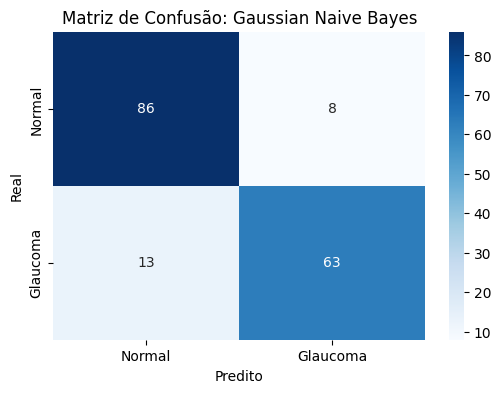

In [14]:
## Quinto Classificador: Naive Bayes com K-Fold (Média ± DP) e Avaliação de Teste Completa

# Importa a biblioteca numpy para manipulação de arrays e cálculo de média/desvio padrão
import numpy as np
# Importa o seaborn para gerar visualizações de mapas de calor (matriz de confusão)
import seaborn as sns
# Importa o matplotlib para renderização e exibição de gráficos na tela
import matplotlib.pyplot as plt
# Importa o classificador Naive Bayes Gaussiano do ecossistema scikit-learn
from sklearn.naive_bayes import GaussianNB
# Importa a função cross_validate para computar múltiplas métricas simultaneamente no K-Fold
from sklearn.model_selection import cross_validate
# Importa o StratifiedKFold para garantir divisões profissionais das classes em cada partição
from sklearn.model_selection import StratifiedKFold
# Importa as funções oficiais de geração de relatórios textuais e matrizes numéricas
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, make_scorer, recall_score

# ==============================================================================
# 1. DEFINIÇÃO DOS ATRIBUTOS E DAS BASES DE DADOS
# ==============================================================================

X_train = X_train_70
y_train = y_train_70
X_test = X_test_30
y_test = y_test_30

# ==============================================================================
# 2. CONFIGURAÇÃO DO MODELO BASE (NAIVE BAYES GAUSSIANO)
# ==============================================================================

print("📡 Inicializando o classificador Gaussian Naive Bayes...")

# O Naive Bayes clássico não possui hiperparâmetros críticos de tuning como os outros,
# pois estima diretamente as probabilidades a partir da distribuição dos dados.
clf_nb = GaussianNB()

# Treina o modelo na base de treino para a avaliação final posterior
clf_nb.fit(X_train, y_train)

# ==============================================================================
# 3. VALIDAÇÃO CRUZADA MULTI-MÉTRICA COM O MODELO (MÉDIA ± DP EM %)
# ==============================================================================

print("\n🔄 Executando validação cruzada multi-métrica para extração dos desvios padrões...")

# Define um gerador de folds estratificado e embaralhado para manter a idoneidade estatística
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cria um scorer customizado para a Especificidade, focando no acerto da classe 0 (Normal)
especificidade_scorer = make_scorer(recall_score, pos_label=0)

# Cria o dicionário mapeando os identificadores oficiais para as métricas da sua tabela
metricas_solicitadas = {
    'acuracia': 'accuracy',
    'precisao': 'precision',
    'sensibilidade': 'recall',
    'especificidade': especificidade_scorer,
    'f1_score': 'f1'
}

# Executa o cross_validate computando simultaneamente todas as métricas em cada partição
resultados_cv = cross_validate(
    estimator=clf_nb,
    X=X_train,
    y=y_train,
    cv=cv_estratificado,
    scoring=metricas_solicitadas,
    return_train_score=False
)

# Extrai os arrays com as 5 notas, multiplicando por 100 para transformar em porcentagem (%)
folds_acc  = resultados_cv['test_acuracia'] * 100
folds_prec = resultados_cv['test_precisao'] * 100
folds_sens = resultados_cv['test_sensibilidade'] * 100
folds_esp  = resultados_cv['test_especificidade'] * 100
folds_f1   = resultados_cv['test_f1_score'] * 100

# ==============================================================================
# 4. INFERÊNCIA NO CONJUNTO DE TESTE INDEPENDENTE
# ==============================================================================

# Aplica o modelo final para gerar predições discretas na base de teste
y_pred_nb = clf_nb.predict(X_test)
# Gera os scores de probabilidade contínua para monitoramento
y_scores_nb = clf_nb.predict_proba(X_test)[:, 1]

# Calcula a matriz de confusão final para extração manual das métricas complementares
cm = confusion_matrix(y_test, y_pred_nb)
tn, fp, fn, tp = cm.ravel()
especificidade_teste = (tn / (tn + fp)) * 100

# ==============================================================================
# 5. GRAVAÇÃO COMPLETA DOS RESULTADOS EM ARQUIVO TEXTO .TXT
# ==============================================================================

# Abre o arquivo para escrita definindo codificação padrão universal
with open("resultados_nb_kfold_completo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("=====================================================================\n")
    arquivo.write("  RELATÓRIO DE VALIDAÇÃO CRUZADA E TESTE NAIVE BAYES - PORCENTAGEM (%) \n")
    arquivo.write("=====================================================================\n\n")
    
    arquivo.write("Resultados Detalhados por Partição (Fold):\n")
    for i in range(5):
        arquivo.write(f" -> Fold {i+1}:\n")
        arquivo.write(f"    - Acurácia:       {folds_acc[i]:.3f}%\n")
        arquivo.write(f"    - Precisão:       {folds_prec[i]:.3f}%\n")
        arquivo.write(f"    - Sensibilidade:  {folds_sens[i]:.3f}%\n")
        arquivo.write(f"    - Especificidade: {folds_esp[i]:.3f}%\n")
        arquivo.write(f"    - F1-Score:       {folds_f1[i]:.3f}%\n\n")
        
    arquivo.write("=====================================================================\n")
    arquivo.write("MÉTRICAS CONSOLIDADAS DA VALIDAÇÃO CRUZADA NAIVE BAYES (MÉDIA ± DP)\n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f" -> ACURÁCIA:       {np.mean(folds_acc):.3f}% (± {np.std(folds_acc):.3f}%)\n")
    arquivo.write(f" -> PRECISÃO:       {np.mean(folds_prec):.3f}% (± {np.std(folds_prec):.3f}%)\n")
    arquivo.write(f" -> SENSIBILIDADE:  {np.mean(folds_sens):.3f}% (± {np.std(folds_sens):.3f}%)\n")
    arquivo.write(f" -> ESPECIFICIDADE: {np.mean(folds_esp):.3f}% (± {np.std(folds_esp):.3f}%)\n")
    arquivo.write(f" -> F1-SCORE:       {np.mean(folds_f1):.3f}% (± {np.std(folds_f1):.3f}%)\n\n")
    
    arquivo.write("=====================================================================\n")
    arquivo.write("       AVALIAÇÃO NO CONJUNTO DE TESTE INDEPENDENTE (REAL)            \n")
    arquivo.write("=====================================================================\n")
    arquivo.write(f"Acurácia no Teste:       {(accuracy_score(y_test, y_pred_nb)*100):.3f}%\n")
    arquivo.write(f"Especificidade no Teste: {especificidade_teste:.3f}%\n\n")
    arquivo.write("Relatório Detalhado de Classificação (Conjunto de Teste):\n")
    arquivo.write(classification_report(y_test, y_pred_nb, target_names=['Normal', 'Glaucoma'], digits=4))

print("💾 Relatório completo gravado com sucesso em 'resultados_nb_kfold_completo.txt'!")

# ==============================================================================
# 6. EXIBIÇÃO CONSOLIDADA DOS RESULTADOS NO TERMINAL
# ==============================================================================

print("\n" + "="*65)
print("MÉTRICAS DA VALIDAÇÃO CRUZADA NAIVE BAYES (MÉDIA ± DESVIO PADRÃO EM %):")
print("="*65)
print(f"✅ Acurácia:       {np.mean(folds_acc):.3f}% ± {np.std(folds_acc):.3f}%")
print(f"🎯 Precisão:       {np.mean(folds_prec):.3f}% ± {np.std(folds_prec):.3f}%")
print(f"🚀 Sensibilidade:  {np.mean(folds_sens):.3f}% ± {np.std(folds_sens):.3f}%")
print(f"🛡️  Especificidade: {np.mean(folds_esp):.3f}% ± {np.std(folds_esp):.3f}%")
print(f"💎 F1-Score:       {np.mean(folds_f1):.3f}% ± {np.std(folds_f1):.3f}%")
print("="*65)

print("\nRelatório de Classificação Final no Conjunto de Teste Naive Bayes (Mundo Real):")
print(classification_report(y_test, y_pred_nb, target_names=['Normal', 'Glaucoma'], digits=4))

# ==============================================================================
# 7. PLOT DA MATRIZ DE CONFUSÃO VISUAL
# ==============================================================================

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Glaucoma'], yticklabels=['Normal', 'Glaucoma'])
plt.title("Matriz de Confusão: Gaussian Naive Bayes")
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()